<a href="https://colab.research.google.com/github/abdealimak/ML-CW/blob/main/LogisticRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

iris = load_iris()

df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [9]:
print("Dataset shape", df.shape)
print("column names", df.columns)
print("Target classes", iris.target_names)
print(df.info())

Dataset shape (150, 5)
column names Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')
Target classes ['setosa' 'versicolor' 'virginica']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


In [10]:
df = df[df['target'] != 2]

print(df.head())
print(df['target'].value_counts())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  
target
0    50
1    50
Name: count, dtype: int64


In [11]:
X = df.drop('target', axis=1)
y = df['target']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

print(X.head())
print(y.head())

Input shape: (100, 4)
Output shape: (100,)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("training samples:", X_train.shape[0])
print("testing samples:", X_test.shape[0])

training samples: 80
testing samples: 20


In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [14]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

print("Model Training Completed")


Model Training Completed


In [15]:
y_pred = model.predict(X_test_scaled)
print("Actual Values:")
print(y_test.to_numpy())

print("Predicted Values:")
print(y_pred)


Actual Values:
[1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]
Predicted Values:
[1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]


In [16]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy(%):", accuracy*100)

Model Accuracy: 1.0
Model Accuracy(%): 100.0


Confusion Matrix:
[[10  0]
 [ 0 10]]


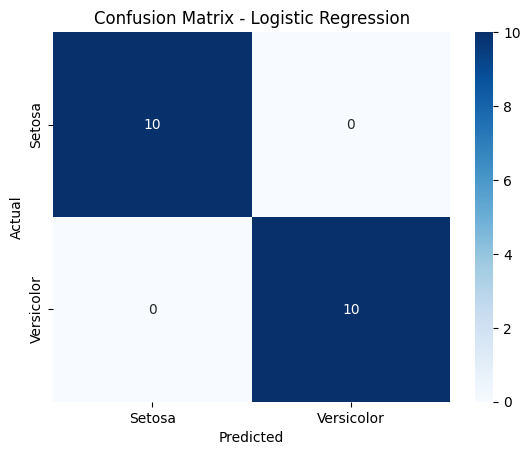

In [17]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Setosa", "Versicolor"],
    yticklabels=["Setosa", "Versicolor"],
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [18]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Setosa", "Versicolor"]
))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



In [20]:
# New flower measurements in the same feature order
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

#Apply the training scaler (Standardizing)
new_flower_scaled = scaler.transform(new_flower)

# Predict the class
prediction = model.predict(new_flower_scaled)

# Predict Class propbabilites

probabilites = model.predict_proba(new_flower_scaled)

# Print the prediction

if prediction[0] == 0:
  print("Predicted species: Setosa")
else:
  print("Predicted species: Versicolor")

print("Class Probabilites:", probabilites)

Predicted species: Setosa
Class Probabilites: [[0.98581743 0.01418257]]


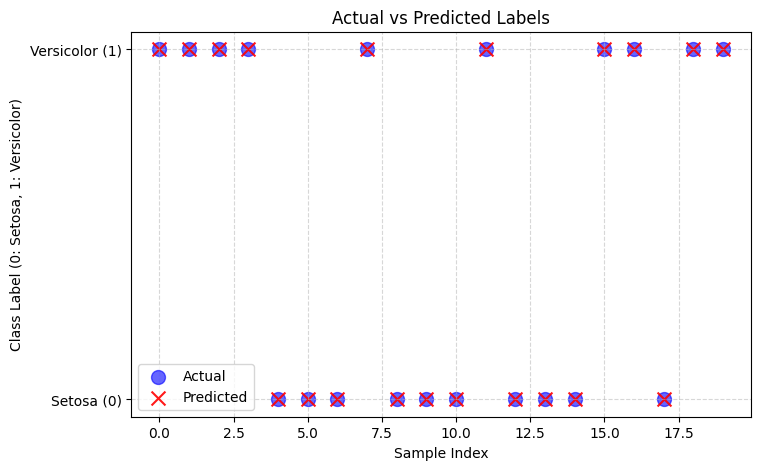

In [22]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 5))

x_indices = np.arange(len(y_test))
plt.scatter(x_indices, y_test.to_numpy(), color='blue', label='Actual', s=100, alpha=0.6)
plt.scatter(x_indices, y_pred, color='red', marker='x', label='Predicted', s=100, alpha=0.9)

plt.title('Actual vs Predicted Labels')
plt.xlabel('Sample Index')
plt.ylabel('Class Label (0: Setosa, 1: Versicolor)')
plt.yticks([0, 1], ['Setosa (0)', 'Versicolor (1)'])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

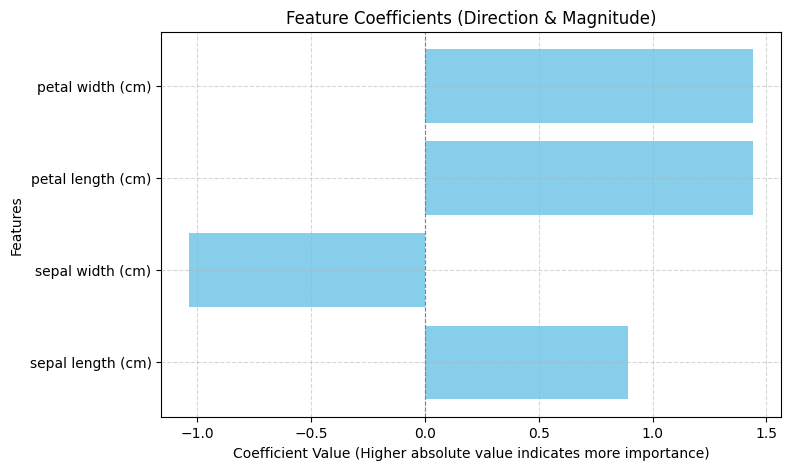

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

coefficients = model.coef_[0]
feature_names = iris.feature_names

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Importance': np.abs(coefficients)
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(feature_importance['Feature'], feature_importance['Coefficient'], color='skyblue')
plt.axvline(x=0, color='grey', linestyle='--', linewidth=0.8)
plt.title('Feature Coefficients (Direction & Magnitude)')
plt.xlabel('Coefficient Value (Higher absolute value indicates more importance)')
plt.ylabel('Features')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()